In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import math
import matplotlib.dates as mdates
import numpy as np

In [2]:
data = pd.read_csv('dane/main data/hydro_klimat_merged_data.csv')

In [3]:
data['Data'] = pd.to_datetime(data['Data'])

In [4]:
data.sort_values(by='Data', inplace=True)

In [5]:
data_ina = data[['Nazwa stacji', 'Data', 'Stan wody [cm]', \
                'Maksymalna temperatura dobowa [°C]', 'Minimalna temperatura dobowa [°C]',\
               'Średnia temperatura dobowa [°C]', 'Temperatura minimalna przy gruncie [°C]', \
                'Suma dobowa opadów nowa [mm]', 'Rodzaj opadu [S/W/]', 'Wysokość pokrywy śnieżnej [cm]',\
                'Nazwa rzeki/jeziora', 'Przepływ [m^3/s]', 'Temperatura wody [st. C]'\
               ]][data['Nazwa rzeki/jeziora'] == 'INA (198)']

data_san = data[['Nazwa stacji', 'Data',  'Stan wody [cm]',\
                'Maksymalna temperatura dobowa [°C]', 'Minimalna temperatura dobowa [°C]',\
               'Średnia temperatura dobowa [°C]', 'Temperatura minimalna przy gruncie [°C]', \
                'Suma dobowa opadów nowa [mm]', 'Rodzaj opadu [S/W/]', 'Wysokość pokrywy śnieżnej [cm]',\
                'Nazwa rzeki/jeziora', 'Przepływ [m^3/s]', 'Temperatura wody [st. C]'\
               ]][data['Nazwa rzeki/jeziora'] == 'SAN (22)'] 

one-hot encoding rodzaj opadu

Zastosowano one-hot encoding na kolumnie ‘Rodzaj opadu’, ponieważ model LSTM wymaga danych liczbowych.

In [6]:
data_ina['Rodzaj opadu [S/W/]'] = data_ina['Rodzaj opadu [S/W/]'].fillna('no_precip')
encoded = pd.get_dummies(data_ina['Rodzaj opadu [S/W/]'], prefix='opad')
data_ina = data_ina.join(encoded)

data_san['Rodzaj opadu [S/W/]'] = data_san['Rodzaj opadu [S/W/]'].fillna('no_precip')
encoded = pd.get_dummies(data_san['Rodzaj opadu [S/W/]'], prefix='opad')
data_san = data_san.join(encoded)

In [7]:
dzien_san = data_san['Data']
suma_opadow_san = data_san['Suma dobowa opadów nowa [mm]']
poziom_wody_san = data_san['Stan wody [cm]']
przeplyw_san = data_san['Przepływ [m^3/s]']
temp_sr_san = data_san['Średnia temperatura dobowa [°C]']
pokr_sn_san = data_san['Wysokość pokrywy śnieżnej [cm]']
temp_min_grunt_san = data_san['Temperatura minimalna przy gruncie [°C]']

In [8]:
dzien_ina = data_ina['Data']
suma_opadow_ina = data_ina['Suma dobowa opadów nowa [mm]']
poziom_wody_ina = data_ina['Stan wody [cm]']
przeplyw_ina = data_ina['Przepływ [m^3/s]']
temp_sr_ina = data_ina['Średnia temperatura dobowa [°C]']
pokr_sn_ina = data_ina['Wysokość pokrywy śnieżnej [cm]']
temp_min_grunt_ina = data_ina['Temperatura minimalna przy gruncie [°C]']

Wykres poziom wód w czasie

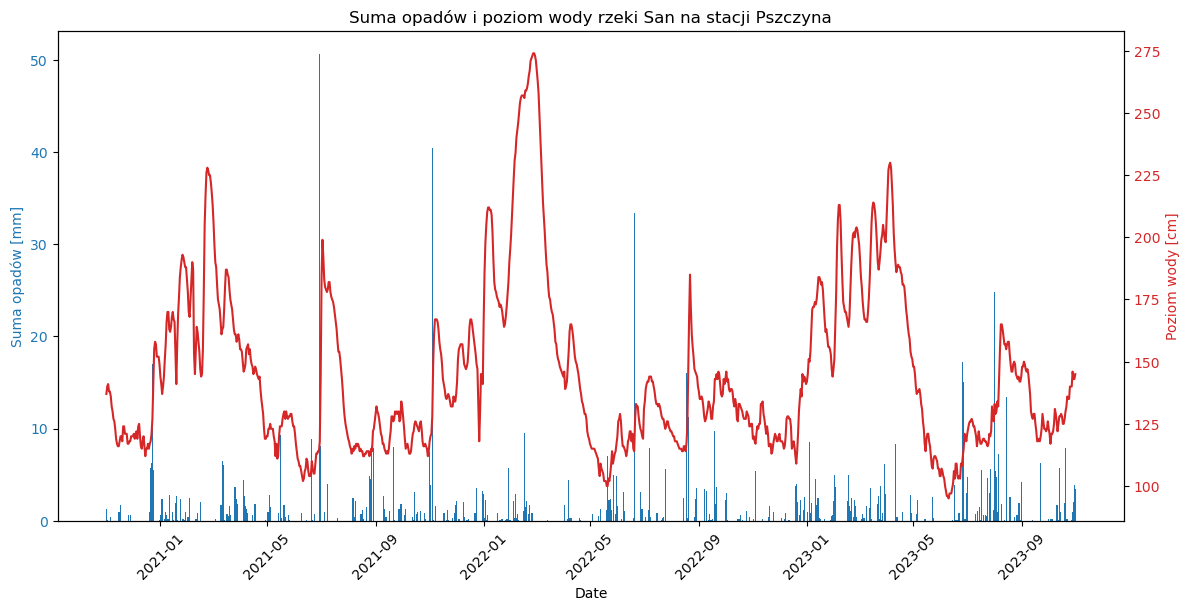

In [9]:
fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:blue'
ax1.set_xlabel('Date')
ax1.set_ylabel('Suma opadów [mm]', color=color)
# ax1.plot(dzien, -suma_opadow_pszcz, color=color)  # Inverse plot for rainfall
ax1.bar(dzien_ina, suma_opadow_ina, color=color)
ax1.tick_params(axis='y', labelcolor=color)

# #ustawienie osi X
# ax1.xaxis.set_major_locator(mdates.DayLocator(interval=30))  # Show every 7 days
# ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))  # Format as YYYY-MM-DD
plt.xticks(rotation=45)

ax2 = ax1.twinx()  # Instantiate a second axes that shares the same x-axis
color = 'tab:red'
ax2.set_ylabel('Poziom wody [cm]', color=color)
ax2.plot(dzien_ina, poziom_wody_ina, color=color)
ax2.tick_params(axis='y', labelcolor=color)

fig.tight_layout()  # To ensure no overlap of y-axis labels
plt.title('Suma opadów i poziom wody rzeki San na stacji Pszczyna')
plt.show()

Wykres za ostatnie 100 dni

In [10]:
data_ina_100 = data_ina.sort_values(by=['Data'])[-100:]
dzien_ina_100 = data_ina_100['Data']
suma_opadow_ina_100 = data_ina_100['Suma dobowa opadów nowa [mm]']
poziom_wody_ina_100 = data_ina_100['Stan wody [cm]']
przeplyw_ina_100 = data_ina_100['Przepływ [m^3/s]']
temp_sr_ina_100 = data_ina_100['Średnia temperatura dobowa [°C]']
pokr_sn_ina_100 = data_ina_100['Wysokość pokrywy śnieżnej [cm]']
temp_min_grunt_ina_100 = data_ina_100['Temperatura minimalna przy gruncie [°C]']

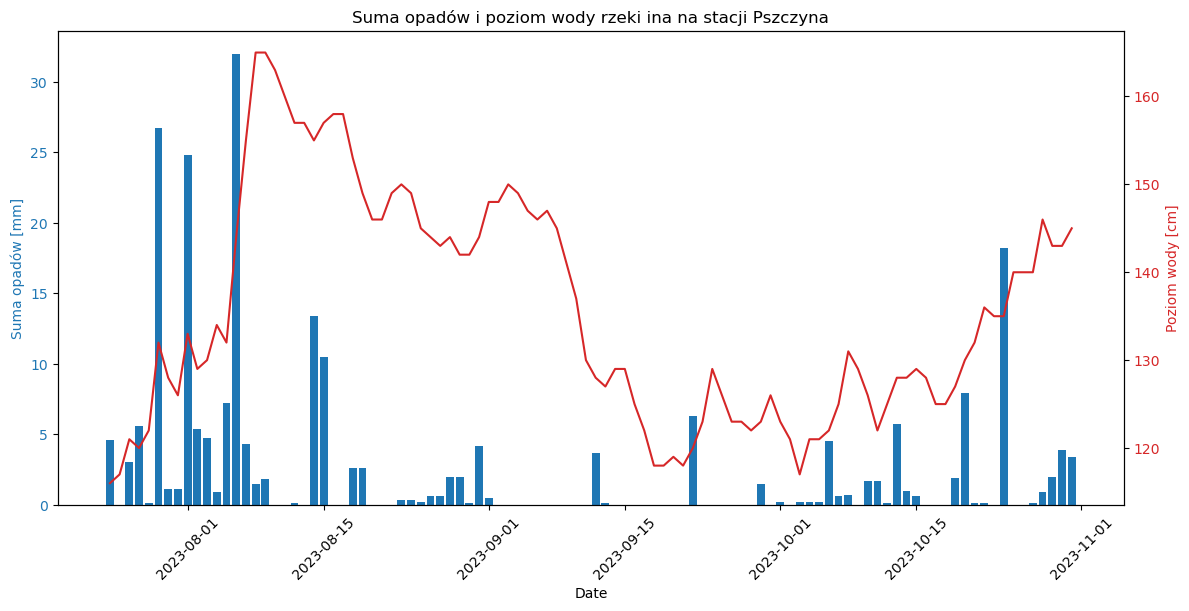

In [11]:
fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:blue'
ax1.set_xlabel('Date')
ax1.set_ylabel('Suma opadów [mm]', color=color)
# ax1.plot(dzien, -suma_opadow_pszcz, color=color)  # Inverse plot for rainfall
ax1.bar(dzien_ina_100, suma_opadow_ina_100, color=color)
ax1.tick_params(axis='y', labelcolor=color)

# #ustawienie osi X
# ax1.xaxis.set_major_locator(mdates.DayLocator(interval=30))  # Show every 7 days
# ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))  # Format as YYYY-MM-DD
plt.xticks(rotation=45)

ax2 = ax1.twinx()  # Instantiate a second axes that shares the same x-axis
color = 'tab:red'
ax2.set_ylabel('Poziom wody [cm]', color=color)
ax2.plot(dzien_ina_100, poziom_wody_ina_100, color=color)
ax2.tick_params(axis='y', labelcolor=color)

fig.tight_layout()  # To ensure no overlap of y-axis labels
plt.title('Suma opadów i poziom wody rzeki ina na stacji Pszczyna')
plt.show()

Usunięcie niepotrzebnych kolumn (wartosci nienumeryczne)

In [12]:
data_ina = data_ina.drop(columns=['Data', 'Rodzaj opadu [S/W/]', 'Nazwa rzeki/jeziora', 'Nazwa stacji',\
                                  'Temperatura wody [st. C]'])

data_san = data_san.drop(columns=['Data', 'Rodzaj opadu [S/W/]', 'Nazwa rzeki/jeziora', 'Nazwa stacji', \
                                  'Temperatura wody [st. C]'])


Podział zbioru

Podział na train, valid, test w proporcji 70/15/15

In [13]:
total_samples_ina = len(data_ina)
train_end_ina = int(total_samples_ina * 0.7)
validation_end_ina = int(total_samples_ina * 0.85)

train_ina = data_ina[:train_end_ina]
validation_ina = data_ina[train_end_ina:validation_end_ina]
test_ina = data_ina[validation_end_ina:]

In [14]:
print(len(train_ina), len(validation_ina), len(test_ina))

766 164 165


#### Utworzenie sekwencji, aby można było predykować na szeregach czasowych 

In [15]:
def create_sequences(input_data, n_steps, n_ahead=1):
    X, y = [], []
    for i in range(len(input_data) - n_steps - n_ahead + 1):
        #indeks końca sekwencji
        end_ix = i + n_steps
        #Tworzenie sekwencji
        seq_x = input_data[i:end_ix, :]  # cechy i poziom wod w sekwencji wybranej dlugosci
        seq_y = input_data[end_ix+n_ahead-1, 0]  # poziom wód nastepnego dnia (lub nastepnego n_ahead dni dalej) po zakresie w wektorze cech
        X.append(seq_x)
        y.append(seq_y)
    return np.array(X), np.array(y)

Wybór sekwencji

In [16]:
train_ina

,Stan wody [cm],Maksymalna temperatura dobowa [°C],Minimalna temperatura dobowa [°C],Średnia temperatura dobowa [°C],Temperatura minimalna przy gruncie [°C],Suma dobowa opadów nowa [mm],Wysokość pokrywy śnieżnej [cm],Przepływ [m^3/s],opad_S,opad_W,opad_no_precip
2373,137,12.3,10.1,11.2,0.0,1.3,0,5.71,0,1,0
2374,140,18.4,12.2,15.6,0.0,0.1,0,5.98,0,1,0
2375,141,17.6,6.2,10.0,0.0,0.0,0,6.04,0,0,1
2376,138,10.7,6.3,7.7,0.0,0.0,0,5.94,0,0,1
2377,138,11.2,2.6,6.7,0.0,0.4,0,5.95,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...
3134,118,2.0,0.0,0.8,0.0,0.0,0,4.81,0,0,1
3135,118,0.0,-2.1,-1.2,0.0,0.3,0,4.84,1,0,0
3136,118,1.5,-1.5,0.3,0.0,0.0,2,4.86,0,0,1
3137,117,1.8,1.1,1.5,0.0,0.9,0,4.83,0,1,0


In [17]:
#uwaga zmiana typu danych!!
train_ina = train_ina.to_numpy()
validation_ina = validation_ina.to_numpy()
test_ina = test_ina.to_numpy()

In [18]:
n_steps = 1 #długość sekwencji

X_train, y_train = create_sequences(train_ina, n_steps=n_steps, n_ahead=1)
X_validation, y_validation = create_sequences(validation_ina, n_steps=n_steps, n_ahead=1)
X_test, y_test = create_sequences(test_ina, n_steps=n_steps, n_ahead=1)

In [15]:
# y_train

Normalizacja zbioru treningowego

In [19]:
X_train.shape #drugi wymiar to n_steps

(765, 1, 11)

In [20]:
n_train, steps, features = X_train.shape
print(features)
print(X_train.reshape(-1, features).shape)
X_train.reshape(-1, features)

11
(765, 11)


array([[137. ,  12.3,  10.1, ...,   0. ,   1. ,   0. ],
       [140. ,  18.4,  12.2, ...,   0. ,   1. ,   0. ],
       [141. ,  17.6,   6.2, ...,   0. ,   0. ,   1. ],
       ...,
       [118. ,   0. ,  -2.1, ...,   1. ,   0. ,   0. ],
       [118. ,   1.5,  -1.5, ...,   0. ,   0. ,   1. ],
       [117. ,   1.8,   1.1, ...,   0. ,   1. ,   0. ]])

In [21]:
from sklearn.preprocessing import StandardScaler

#Zakładamy, że dane mają kształt: (próbki, kroki_czasowe, cechy)
n_train, steps, features = X_train.shape
n_val = X_validation.shape[0]
n_test = X_test.shape[0]

# Przekształcenie do 2D (scalanie kroków czasowych i próbek)
X_train_2d = X_train.reshape(-1, features)
X_val_2d = X_validation.reshape(-1, features)
X_test_2d = X_test.reshape(-1, features)

#Skalowanie
scaler = StandardScaler()
# StandardScaler oblicza średnią i odchylenie tylko z danych treningowych (fit_transform)
X_train_scaled = scaler.fit_transform(X_train_2d) 
#Potem tę samą skalę stosujemy do walidacji i testu (transform) (ochrona przed data_leakage)
X_val_scaled = scaler.transform(X_val_2d)
X_test_scaled = scaler.transform(X_test_2d)

# Przywrócenie oryginalnych kształtów
X_train = X_train_scaled.reshape(n_train, steps, features)
X_validation = X_val_scaled.reshape(n_val, steps, features)
X_test = X_test_scaled.reshape(n_test, steps, features)

In [22]:
X_train.shape

(765, 1, 11)

In [20]:
# mean_train_san = train_san.mean(axis=0)
# train_san -= mean_train_san
# std_san = train_san.std(axis=0)
# train_san /= std_san

In [23]:
#sprawdzenie zmienności zmiennej celu
print(y_train.min(), y_train.max())
print(np.mean(y_train), np.std(y_train))
#zmienność nei jest zbyt duża, dlatego nie skaluję na razie

100.0 274.0
144.37908496732027 34.817245846175744


In [22]:
# #do ewentulanego przetestowania czy poprawi wyniki
# from sklearn.preprocessing import StandardScaler

# y_scaler = StandardScaler()
# y_train_scaled = y_scaler.fit_transform(y_train.reshape(-1, 1))
# y_val_scaled = y_scaler.transform(y_validation.reshape(-1, 1))
# y_test_scaled = y_scaler.transform(y_test.reshape(-1, 1))


Punkt odniesienia (sprawdzenie y_train_san, jaki będzie błąd, gdy przyjmiemy, że poziom jutro będzie taki sam jak dziś)

miara błędu MAE

In [23]:
# np.mean(np.abs(y_validation[-2]-y_validation[-1]))

In [24]:
#czyli na danych nienormalizowanych 
# 0.44248616167015586 * np.std(validation_san[:, 1]) #musi być san bo sprawdam std przed walidacją
# 3.8cm

In [25]:
# validation_san[:, 1]

In [24]:
#na całości, kod z DL Chollet strona 222
def evaluate_naive_method():
    batch_maes = []
    for i, step in enumerate(range(len(y_validation)-1)):
        preds, targets = y_validation[i], y_validation[i+1]
        mae = np.mean(np.abs(preds - targets))
        batch_maes.append(mae)
    return np.mean(batch_maes)
    
print(evaluate_naive_method())
#gdyby patrzeć tylko na dzień poprzedni o ile średnio taki wynik by się mylił (uwaga! miara mae taka jak w modelu!)

3.962962962962963


Płaska sieć z jedną gęstą warstwą (str 494 ML)

In [27]:
X_train.shape[-1]

11

In [25]:
# from keras.models import Sequential
# from keras import layers
# from keras.layers import Flatten, Dense
import keras

model = keras.models.Sequential([
    keras.layers.Flatten(input_shape=[n_steps, X_train.shape[-1]]), #input_shape = (timesteps, features)
    keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mae')

C:\Users\kinga\AppData\Local\anaconda3\lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [26]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    validation_data=(X_validation, y_validation)
)

Epoch 1/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 146.9765 - val_loss: 169.7302
Epoch 2/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 142.3592 - val_loss: 169.7179
Epoch 3/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 144.2975 - val_loss: 169.6881
Epoch 4/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 142.4771 - val_loss: 169.6751
Epoch 5/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 142.5726 - val_loss: 169.6495
Epoch 6/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 144.9095 - val_loss: 169.6142
Epoch 7/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 145.7052 - val_loss: 169.5928
Epoch 8/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 145.6291 - val_loss: 169.5626
Epoch 9/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 143.3571 - val_loss: 169.5492
Epoch 10/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 145.5638 - val_loss: 169.5187
Epoch 11/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 143.0333 - val_loss: 169.4975
Epoch 12/20
24/24 ━━━━━━━━━━━━

In [35]:
# plt.figure(figsize=(10, 6))
# plt.plot(history.history['loss'], label='Training Loss')
# plt.plot(history.history['val_loss'], label='Validation Loss')
# plt.title('Model Training History')
# plt.xlabel('Epoch')
# plt.ylabel('Loss')
# plt.legend()
# plt.grid(True)
# plt.show()

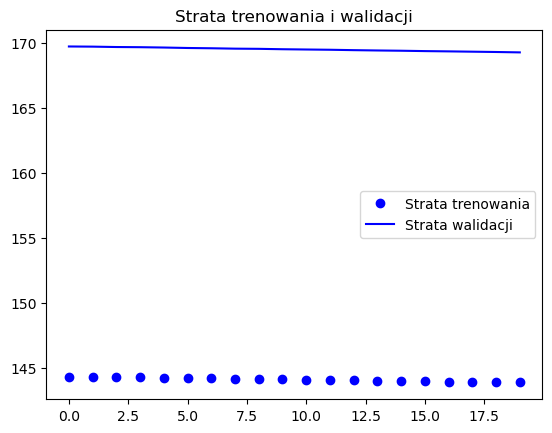

In [27]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

In [28]:
min(val_loss)

169.27627563476562

Prosty model rekurencyjny

In [38]:
X_train.shape

(765, 1, 11)

In [39]:
# X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))

In [29]:
# import keras

model = keras.models.Sequential([
    keras.layers.SimpleRNN(1, input_shape=[None, X_train.shape[2]]) #tutaj daję wartość none, żeby mogła wykryć zalezności czasowe
])

model.compile(optimizer='adam', loss='mae')

C:\Users\kinga\AppData\Local\anaconda3\lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [30]:
history = model.fit(
    X_train, y_train,
    epochs=30,
    validation_data=(X_validation, y_validation)
)

Epoch 1/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 145.2105 - val_loss: 168.3417
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 143.6629 - val_loss: 168.3308
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 143.8876 - val_loss: 168.3132
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 143.6664 - val_loss: 168.2992
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 145.1288 - val_loss: 168.2868
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 144.3498 - val_loss: 168.2746
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 142.4934 - val_loss: 168.2644
Epoch 8/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 144.1687 - val_loss: 168.2533
Epoch 9/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 143.9519 - val_loss: 168.2380
Epoch 10/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 144.2163 - val_loss: 168.2260
Epoch 11/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 145.0309 - val_loss: 168.2120
Epoch 12/30
24/24 ━━━━━━━━━━━

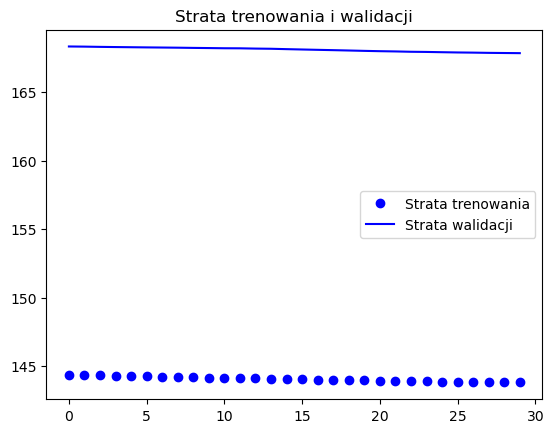

In [31]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

In [32]:
min(val_loss) #źle to wygląda

167.85409545898438

Prosty model LSTM

In [33]:
model = keras.models.Sequential([
    keras.layers.LSTM(64, activation='relu', input_shape=(n_steps, X_train.shape[2])),  # '2' represents the number of features in each time step
#     keras.layers.BatchNormalization(), nie poprawiła
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mae')


In [34]:
history = model.fit(
    X_train, y_train,
    epochs=100, #widać, że więcej warstw moze pomóc
    validation_data=(X_validation, y_validation)
)

Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 144.8221 - val_loss: 168.3943
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 145.6646 - val_loss: 168.2713
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 145.1994 - val_loss: 168.0566
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 144.6280 - val_loss: 167.6464
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 142.8083 - val_loss: 166.8596
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 141.5363 - val_loss: 165.4219
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 138.9118 - val_loss: 162.9432
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 132.7499 - val_loss: 159.0714
Epoch 9/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 127.0005 - val_loss: 153.4667
Epoch 10/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 119.2756 - val_loss: 145.7517
Epoch 11/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 106.6716 - val_loss: 135.9372
Epoch 12/100
24/24

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.1002 - val_loss: 5.0642
Epoch 69/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 4.0868 - val_loss: 4.9890
Epoch 70/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 3.9223 - val_loss: 5.0579
Epoch 71/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.1386 - val_loss: 5.0619
Epoch 72/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 3.7632 - val_loss: 5.0265
Epoch 73/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 3.9768 - val_loss: 5.0083
Epoch 74/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 3.9058 - val_loss: 4.9758
Epoch 75/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 3.5603 - val_loss: 4.9642
Epoch 76/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.8673 - val_loss: 4.9812
Epoch 77/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.1213 - val_loss: 4.9171
Epoch 78/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.5759 - val_loss: 4.8874
Epoch 79/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.4834 

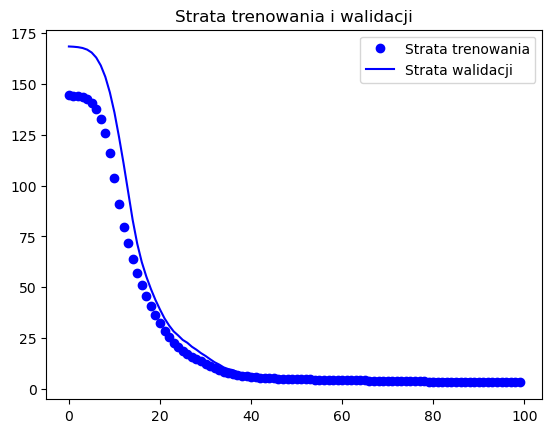

In [35]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

In [36]:
min(val_loss) # o wiele lepiej, ale gorzej niż wartość bazowa

4.541769504547119

Model ze stosem warstw rekurencyjnych

In [37]:
model = keras.models.Sequential([
    keras.layers.LSTM(64, activation='relu', input_shape=(n_steps, X_train.shape[2]),\
                      return_sequences=True),  # warstwa zwraca pełne sekencje wyjściowe (tensory trójwymiarowe)
    keras.layers.LSTM(32, activation='relu', return_sequences=True),
    keras.layers.LSTM(8, activation='relu', return_sequences=True),
    keras.layers.LSTM(16, activation='relu'),
    keras.layers.Dense(4, activation="relu"),
    keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mae')

In [38]:
history = model.fit(
    X_train, y_train,
    epochs=50,
    validation_data=(X_validation, y_validation)
)

Epoch 1/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 43ms/step - loss: 145.5392 - val_loss: 168.4348
Epoch 2/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 143.8223 - val_loss: 168.4069
Epoch 3/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 144.0776 - val_loss: 168.3737
Epoch 4/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 145.6434 - val_loss: 168.3117
Epoch 5/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 144.3746 - val_loss: 166.9076
Epoch 6/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 140.3707 - val_loss: 152.3153
Epoch 7/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 123.6968 - val_loss: 99.0538
Epoch 8/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 79.9583 - val_loss: 78.1738
Epoch 9/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 54.4765 - val_loss: 63.5676
Epoch 10/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 44.2442 - val_loss: 52.4311
Epoch 11/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 36.5685 - val_loss: 42.4089
Epoch 12/50
24/24 ━━━━━━━━━━━━━━━━━━━━

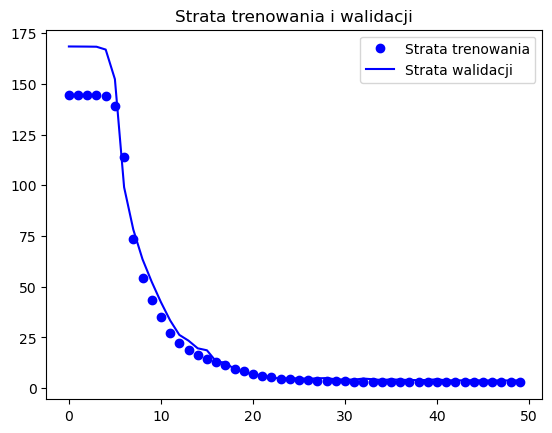

In [39]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

In [40]:
min(val_loss)

3.7726383209228516

Lstm ze stosem warstw z mniejszą liczbą neuronów w każdej

In [41]:
model = keras.models.Sequential([
    keras.layers.LSTM(32, activation='relu', input_shape=(n_steps, X_train.shape[2]),\
                      return_sequences=True),  # warstwa zwraca pełne sekencje wyjściowe (tensory trójwymiarowe)
    keras.layers.LSTM(8, activation='relu'),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mae')

In [42]:
history = model.fit(
    X_train, y_train,
    epochs=30,
    validation_data=(X_validation, y_validation)
)

Epoch 1/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 144.0310 - val_loss: 168.3919
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 143.5290 - val_loss: 168.2671
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 143.3906 - val_loss: 168.0059
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 145.0597 - val_loss: 167.3078
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 143.3811 - val_loss: 164.6413
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 142.6135 - val_loss: 156.4169
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 132.3707 - val_loss: 138.6231
Epoch 8/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 114.0238 - val_loss: 108.0844
Epoch 9/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 90.8178 - val_loss: 78.9366
Epoch 10/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 69.6356 - val_loss: 68.4352
Epoch 11/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 53.2623 - val_loss: 59.0861
Epoch 12/30
24/24 ━━━━━━━━━━━━━━━━━

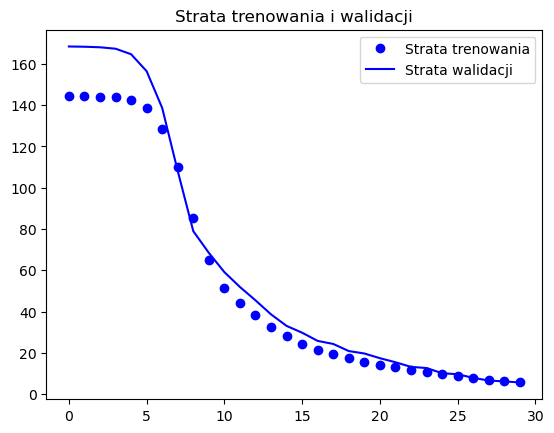

In [43]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

In [44]:
min(val_loss)

5.637983798980713

Lstm ze stosem większej liczby warstw

In [45]:
model = keras.models.Sequential([
    keras.layers.LSTM(64, activation='relu', input_shape=(n_steps, X_train.shape[2]),\
                      return_sequences=True),  # warstwa zwraca pełne sekencje wyjściowe (tensory trójwymiarowe)
    keras.layers.LSTM(32, activation='relu', return_sequences=True),
    keras.layers.LSTM(16, activation='relu', return_sequences=True),
    keras.layers.LSTM(8, activation='relu'),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mae')

In [46]:
history = model.fit(
    X_train, y_train,
    epochs=30,
    validation_data=(X_validation, y_validation)
)

Epoch 1/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - loss: 143.4726 - val_loss: 168.3996
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 141.6595 - val_loss: 168.3166
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 142.9778 - val_loss: 168.0301
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 143.5416 - val_loss: 159.8421
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 128.6163 - val_loss: 103.5880
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 81.5416 - val_loss: 69.9267
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 57.5197 - val_loss: 54.1684
Epoch 8/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 42.6794 - val_loss: 43.8988
Epoch 9/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 31.9450 - val_loss: 34.7003
Epoch 10/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 25.1745 - val_loss: 28.1026
Epoch 11/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 20.0553 - val_loss: 23.8357
Epoch 12/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s

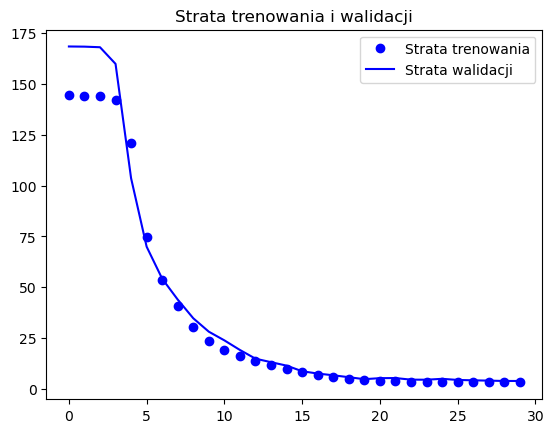

In [47]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

In [48]:
min(val_loss) 

3.863316774368286

Model lstm jak w ML STR  503 (modyfikacja zmiana f. aktywacji)

In [49]:
model = keras.models.Sequential([
    keras.layers.LSTM(32,activation='relu', input_shape=(n_steps, X_train.shape[2]), return_sequences=True),
    keras.layers.LSTM(20,activation='relu' ),  # return_sequences=False (domyślnie)
    keras.layers.Dense(1) # keras.layers.TimeDistributed(keras.layers.Dense(1)) dawał by y_predict jako (batch_size, n_steps, 1)
])


model.compile(optimizer='adam', loss='mae')

In [50]:
history = model.fit(
    X_train, y_train,
    epochs=100,
    validation_data=(X_validation, y_validation)
)

Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 143.9870 - val_loss: 168.3668
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 144.2852 - val_loss: 168.2051
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 145.8456 - val_loss: 167.8157
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 145.3549 - val_loss: 166.6033
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 140.7484 - val_loss: 162.9283
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 134.9365 - val_loss: 155.3355
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 127.2079 - val_loss: 143.4771
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 109.8417 - val_loss: 127.2381
Epoch 9/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 92.1467 - val_loss: 106.8575
Epoch 10/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 76.2683 - val_loss: 85.6871
Epoch 11/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 61.5671 - val_loss: 71.0486
Epoch 12/100
24/24 ━━━━

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 3.1333 - val_loss: 4.9052
Epoch 69/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 3.3666 - val_loss: 4.7582
Epoch 70/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 3.2651 - val_loss: 4.7656
Epoch 71/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.3821 - val_loss: 4.6859
Epoch 72/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.1918 - val_loss: 4.6746
Epoch 73/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.2190 - val_loss: 4.6898
Epoch 74/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.3161 - val_loss: 4.6358
Epoch 75/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.4160 - val_loss: 4.6167
Epoch 76/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.4466 - val_loss: 4.5849
Epoch 77/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.3312 - val_loss: 4.6374
Epoch 78/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.8933 - val_loss: 4.4821
Epoch 79/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.2217 

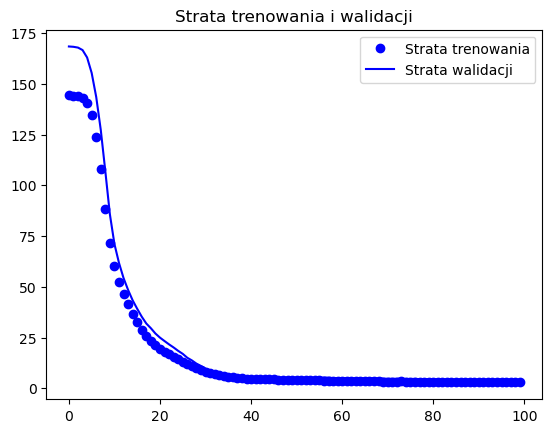

In [51]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

In [52]:
min(val_loss)

4.103395462036133

### optymalizacja hiperparametrów 3 najlepszych modeli

#### model nr 1

In [53]:
import keras_tuner as kt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import MeanAbsoluteError

# Budowanie modelu z przestrzenią hiperparametrów
def build_model_1(hp):
    model = Sequential()
    
    # Liczba neuronów LSTM
    model.add(LSTM(
        units=hp.Int('units_lstm1', min_value=8, max_value=64, step=8),
        activation='relu',
        return_sequences = True,
        input_shape=(n_steps, X_train.shape[2])
    ))
    
    model.add(LSTM(
        units=hp.Int('units_lstm2', min_value=8, max_value=32, step=4),
        activation='relu',
        return_sequences = True
    ))
    
    model.add(LSTM(
        units=hp.Int('units_lstm3', min_value=4, max_value=16, step=2),
        activation='relu',
        return_sequences = True
    ))
    
    model.add(LSTM(
        units=hp.Int('units_lstm4', min_value=4, max_value=16, step=2),
        activation='relu'
    ))
    
    # Gęsta warstwa
    model.add(Dense(
        units=hp.Int('units_dense', min_value=1, max_value=8, step=2),
        activation='relu'
    ))

    # Wyjście
    model.add(Dense(1))

    # Optymalizator (tu: learning rate jako hiperparametr)
    model.compile(
        optimizer=Adam(
            hp.Float('learning_rate', 1e-4, 1e-2, sampling='log')
        ),
        loss=MeanAbsoluteError()
    )
    
    return model

In [54]:
from keras_tuner.tuners import RandomSearch

tuner = RandomSearch(
    build_model_1,
    objective='val_loss',
    max_trials=10,  # liczba różnych konfiguracji do przetestowania
    executions_per_trial=1,
    directory='my_dir',
    project_name='lstm_tuning',
    overwrite=True  # <<< TO ZRESETUJE tuner
)

tuner.search(X_train, y_train, 
             epochs=20, 
             validation_data=(X_validation, y_validation),
             callbacks=[])

# Wyświetlenie najlepszych hiperparametrów
best_hps = tuner.get_best_hyperparameters(1)[0]
print(f"Najlepsze hiperparametry: LSTM: {best_hps.get('units_lstm1')}, {best_hps.get('units_lstm2')},\
{best_hps.get('units_lstm3')},{best_hps.get('units_lstm4')}, Dense: {best_hps.get('units_dense')},\
LR: {best_hps.get('learning_rate')}")


Trial 10 Complete [00h 00m 19s]
val_loss: 167.20953369140625

Best val_loss So Far: 3.8194284439086914
Total elapsed time: 00h 02m 25s
Najlepsze hiperparametry: LSTM: 56, 12,4,6, Dense: 7,LR: 0.007295617754800786


In [55]:
model = keras.models.Sequential([
    keras.layers.LSTM(56, activation='relu', input_shape=(n_steps, X_train.shape[2]),\
                      return_sequences=True),  # warstwa zwraca pełne sekencje wyjściowe (tensory trójwymiarowe)
    keras.layers.LSTM(12, activation='relu', return_sequences=True),
    keras.layers.LSTM(4, activation='relu', return_sequences=True),
    keras.layers.LSTM(6, activation='relu'),
    keras.layers.Dense(7, activation="relu"),
    keras.layers.Dense(1)
])

optimizer = keras.optimizers.Adam(learning_rate=0.007295617754800786)
model.compile(optimizer=optimizer, loss='mae')

#########

history = model.fit(
    X_train, y_train,
    epochs=100,
    validation_data=(X_validation, y_validation)
)

Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - loss: 144.4956 - val_loss: 166.6705
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 129.2192 - val_loss: 78.6432
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 52.1334 - val_loss: 28.3501
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 20.7341 - val_loss: 19.3303
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 13.4449 - val_loss: 9.9139
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 8.6653 - val_loss: 6.9871
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.3547 - val_loss: 7.2981
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 5.3535 - val_loss: 5.3657
Epoch 9/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 4.3599 - val_loss: 5.8416
Epoch 10/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 4.6481 - val_loss: 5.7270
Epoch 11/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 3.7956 - val_loss: 4.6133
Epoch 12/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/ste

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 3.4249 - val_loss: 4.6657
Epoch 70/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.4949 - val_loss: 4.0270
Epoch 71/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.9827 - val_loss: 5.8386
Epoch 72/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.0913 - val_loss: 3.9468
Epoch 73/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 3.7195 - val_loss: 4.0737
Epoch 74/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 2.8426 - val_loss: 3.8940
Epoch 75/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 2.7527 - val_loss: 3.7031
Epoch 76/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 3.1743 - val_loss: 4.3403
Epoch 77/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 3.1785 - val_loss: 3.6206
Epoch 78/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 3.0886 - val_loss: 4.9429
Epoch 79/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 3.2666 - val_loss: 4.2968
Epoch 80/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 2.8963 

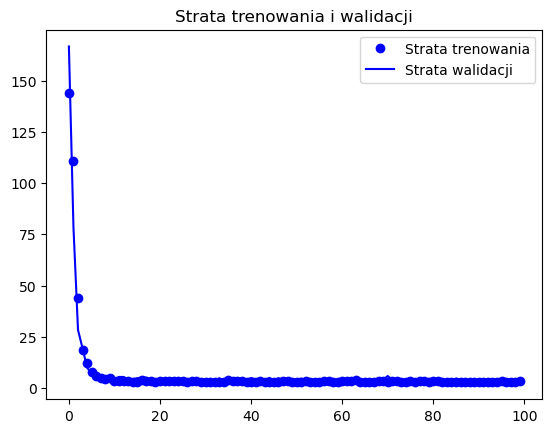

3.620628595352173


In [56]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

####################
print(min(val_loss))

#### model nr 2 miał te same wartswy co 1, więc zawiera sie w powyzszej hiperoptymalizacji

#### Model 3

In [57]:
# Budowanie modelu z przestrzenią hiperparametrów
def build_model_3(hp):
    model = Sequential()
    
    # Liczba neuronów LSTM
    model.add(LSTM(
        units=hp.Int('units_lstm1', min_value=8, max_value=64, step=8),
        activation='relu',
        return_sequences = True,
        input_shape=(n_steps, X_train.shape[2])
    ))
    
    model.add(LSTM(
        units=hp.Int('units_lstm2', min_value=8, max_value=32, step=2),
        activation='relu'
    ))

    # Wyjście
    model.add(Dense(1))

    # Optymalizator (tu: learning rate jako hiperparametr)
    model.compile(
        optimizer=Adam(
            hp.Float('learning_rate', 1e-4, 1e-2, sampling='log')
        ),
        loss=MeanAbsoluteError()
    )
    
    return model

In [58]:
from keras_tuner.tuners import RandomSearch

tuner = RandomSearch(
    build_model_3,
    objective='val_loss',
    max_trials=10,  # liczba różnych konfiguracji do przetestowania
    executions_per_trial=1,
    directory='my_dir',
    project_name='lstm_tuning',
    overwrite=True  # <<< TO ZRESETUJE tuner
)

tuner.search(X_train, y_train, 
             epochs=20, 
             validation_data=(X_validation, y_validation),
             callbacks=[])

# Wyświetlenie najlepszych hiperparametrów
best_hps = tuner.get_best_hyperparameters(1)[0]
print(f"Najlepsze hiperparametry: LSTM: {best_hps.get('units_lstm1')}, {best_hps.get('units_lstm2')},\
LR: {best_hps.get('learning_rate')}")


Trial 10 Complete [00h 00m 08s]
val_loss: 4.071765899658203

Best val_loss So Far: 3.7050158977508545
Total elapsed time: 00h 01m 46s
Najlepsze hiperparametry: LSTM: 64, 20,LR: 0.004170004462263622


In [59]:
model = keras.models.Sequential([
    keras.layers.LSTM(64,activation='relu', input_shape=(n_steps, X_train.shape[2]), return_sequences=True),
    keras.layers.LSTM(20,activation='relu' ),  # return_sequences=False (domyślnie)
    keras.layers.Dense(1) 
])

optimizer = keras.optimizers.Adam(learning_rate=0.004170004462263622)
model.compile(optimizer=optimizer, loss='mae')

#########

history = model.fit(
    X_train, y_train,
    epochs=100,
    validation_data=(X_validation, y_validation)
)

Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 144.9678 - val_loss: 166.7180
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 139.7368 - val_loss: 139.1519
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 90.3461 - val_loss: 69.7698
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 52.1042 - val_loss: 42.5462
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 28.6645 - val_loss: 25.9094
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 17.9024 - val_loss: 18.5563
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 12.0013 - val_loss: 11.3378
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 9.5468 - val_loss: 8.1966
Epoch 9/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 6.8814 - val_loss: 6.0660
Epoch 10/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.3096 - val_loss: 5.7002
Epoch 11/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.5380 - val_loss: 5.6362
Epoch 12/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.5511 - val_loss: 3.8133
Epoch 70/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.4921 - val_loss: 3.7617
Epoch 71/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.5407 - val_loss: 3.9020
Epoch 72/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.9084 - val_loss: 4.0465
Epoch 73/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.7985 - val_loss: 3.8622
Epoch 74/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.8611 - val_loss: 3.8480
Epoch 75/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.6452 - val_loss: 3.7478
Epoch 76/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.5132 - val_loss: 3.7994
Epoch 77/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.6808 - val_loss: 3.6149
Epoch 78/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.6520 - val_loss: 3.8441
Epoch 79/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.9964 - val_loss: 3.7021
Epoch 80/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.6871 

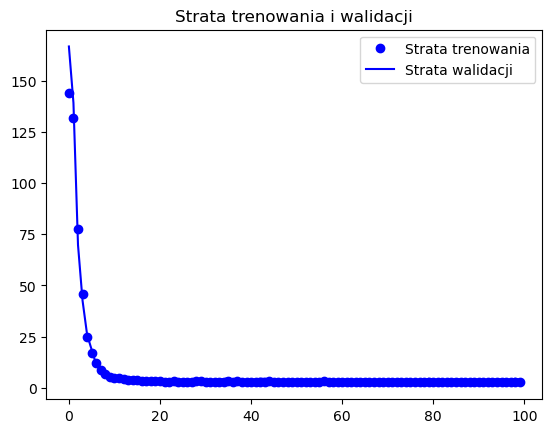

3.5748376846313477


In [60]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

####################
print(min(val_loss))

### Najlepszy model z regularyzacją

#### early stopping

In [111]:
model = keras.models.Sequential([
    keras.layers.LSTM(64,activation='relu', input_shape=(n_steps, X_train.shape[2]), return_sequences=True),
    keras.layers.LSTM(20,activation='relu' ),  # return_sequences=False (domyślnie)
    keras.layers.Dense(1) 
])

optimizer = keras.optimizers.Adam(learning_rate=0.004170004462263622)
model.compile(optimizer=optimizer, loss='mae')

In [112]:
model.summary()

Model: "sequential_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_48 (LSTM)                       │ (None, 1, 64)               │          19,456 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_49 (LSTM)                       │ (None, 20)                  │           6,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_24 (Dense)                     │ (None, 1)                   │              21 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 26,277 (102.64 KB)

 Trainable params: 26,277 (102.64 KB)

 Non-trainable params: 0 (0.00 B)

In [113]:
from tensorflow.keras.callbacks import EarlyStopping

# Tworzenie callbacku EarlyStopping
early_stopping = EarlyStopping(
    monitor='val_loss',       # monitorowanie straty walidacyjnej
    patience=20,              #liczba epok bez poprawy, po których zatrzyma trenowanie
    restore_best_weights=True  # przywróć najlepsze wagi po zatrzymaniu
)

history = model.fit(
    X_train, y_train,
    epochs=100,
    validation_data=(X_validation, y_validation),
    callbacks=[early_stopping]
)

Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 143.9281 - val_loss: 167.5737
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 142.3619 - val_loss: 153.3853
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 115.5689 - val_loss: 93.6297
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 62.7198 - val_loss: 66.1052
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 45.7031 - val_loss: 45.2321
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 28.0145 - val_loss: 26.4384
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 18.9113 - val_loss: 19.2208
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 14.1301 - val_loss: 13.5147
Epoch 9/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 11.4174 - val_loss: 8.6052
Epoch 10/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 7.3551 - val_loss: 6.5687
Epoch 11/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 6.0227 - val_loss: 7.3035
Epoch 12/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.4652 - val_loss: 4.0635
Epoch 70/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.4908 - val_loss: 3.9881
Epoch 71/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.6226 - val_loss: 3.7129
Epoch 72/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2.6874 - val_loss: 3.6855
Epoch 73/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.6270 - val_loss: 3.8653
Epoch 74/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.6645 - val_loss: 3.7932
Epoch 75/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.6046 - val_loss: 4.2787
Epoch 76/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.7610 - val_loss: 3.9940
Epoch 77/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.5207 - val_loss: 3.6509
Epoch 78/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.5823 - val_loss: 3.7434
Epoch 79/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.5376 - val_loss: 4.2380
Epoch 80/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.6667 

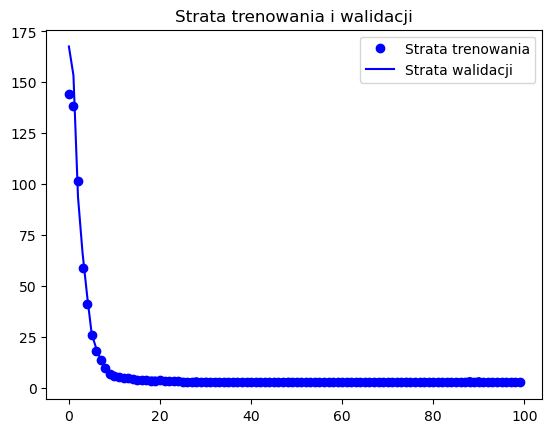

3.6075634956359863


In [114]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

####################
print(min(val_loss))

#### l1

In [106]:
from keras.models import Sequential
from keras.layers import Input, LSTM, Dense
from keras.regularizers import l1
from keras.optimizers import Adam

# Ustal poziom regularyzacji L1
l1_reg = 1e-5  # lambda karanie wag

model = Sequential([   
    keras.layers.LSTM(64,activation='relu', input_shape=(n_steps, X_train.shape[2]), return_sequences=True,kernel_regularizer=l1(l1_reg)),
    keras.layers.LSTM(20,activation='relu',kernel_regularizer=l1(l1_reg)),  # return_sequences=False (domyślnie)
    keras.layers.Dense(1) 
])

optimizer = keras.optimizers.Adam(learning_rate=0.004170004462263622)
model.compile(optimizer=optimizer, loss='mae')


#########

history = model.fit(
    X_train, y_train,
    epochs=100,
    validation_data=(X_validation, y_validation)
)

Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - loss: 145.0669 - val_loss: 167.5605
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 141.0039 - val_loss: 151.1762
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 110.3426 - val_loss: 86.3799
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 63.2532 - val_loss: 58.2886
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 44.4746 - val_loss: 37.1080
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 26.4916 - val_loss: 26.2440
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 17.9037 - val_loss: 19.3272
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 13.5141 - val_loss: 11.2144
Epoch 9/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 9.2309 - val_loss: 6.6936
Epoch 10/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 5.6039 - val_loss: 6.5171
Epoch 11/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.4555 - val_loss: 5.8106
Epoch 12/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.8730 - val_loss: 3.6210
Epoch 70/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.9376 - val_loss: 4.0850
Epoch 71/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.7795 - val_loss: 4.3275
Epoch 72/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.8750 - val_loss: 3.7030
Epoch 73/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.9110 - val_loss: 3.7469
Epoch 74/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.8033 - val_loss: 4.2125
Epoch 75/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.7427 - val_loss: 3.8645
Epoch 76/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.4814 - val_loss: 3.7918
Epoch 77/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.6076 - val_loss: 3.7144
Epoch 78/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.4975 - val_loss: 3.7558
Epoch 79/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 3.1561 - val_loss: 4.0365
Epoch 80/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.5909 

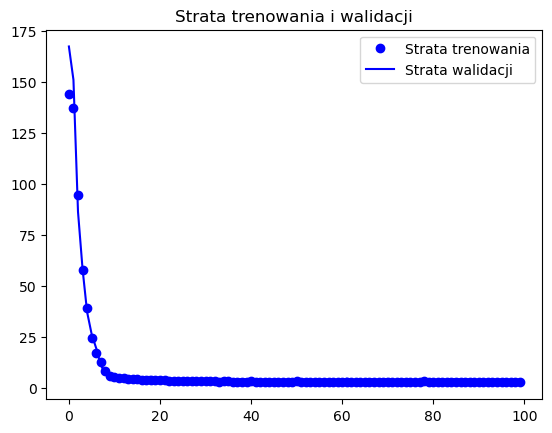

3.621033191680908


In [107]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

####################
print(min(val_loss))

#### l2

In [104]:
from keras.models import Sequential
from keras.layers import Input, LSTM, Dense
from keras.regularizers import l1, l2
from keras.optimizers import Adam

# Ustal poziom regularyzacji L1
l2_reg = 1e-5  # lambda karanie wag

model = Sequential([   
    keras.layers.LSTM(64,activation='relu', input_shape=(n_steps, X_train.shape[2]),\
                      return_sequences=True,kernel_regularizer=l2(l2_reg)),
    keras.layers.LSTM(20,activation='relu',kernel_regularizer=l2(l2_reg)),  # return_sequences=False (domyślnie)
    keras.layers.Dense(1) 
])

optimizer = keras.optimizers.Adam(learning_rate=0.004170004462263622)
model.compile(optimizer=optimizer, loss='mae')


#########

history = model.fit(
    X_train, y_train,
    epochs=100,
    validation_data=(X_validation, y_validation)
)

Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - loss: 144.8317 - val_loss: 166.9991
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 141.6071 - val_loss: 144.6436
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 107.4136 - val_loss: 76.0327
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 53.2934 - val_loss: 50.6815
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 34.8311 - val_loss: 31.5517
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 20.7764 - val_loss: 22.5960
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 15.5251 - val_loss: 15.3652
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 11.3497 - val_loss: 7.6093
Epoch 9/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.6249 - val_loss: 6.6668
Epoch 10/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 6.1011 - val_loss: 5.5495
Epoch 11/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.0122 - val_loss: 5.7706
Epoch 12/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.5457 - val_loss: 3.8567
Epoch 70/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.5898 - val_loss: 4.1343
Epoch 71/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.6844 - val_loss: 3.9298
Epoch 72/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.6256 - val_loss: 4.4715
Epoch 73/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.8510 - val_loss: 3.9698
Epoch 74/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.5823 - val_loss: 4.3016
Epoch 75/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.7677 - val_loss: 3.6741
Epoch 76/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.7526 - val_loss: 3.7638
Epoch 77/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.4565 - val_loss: 3.6322
Epoch 78/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.8469 - val_loss: 3.9150
Epoch 79/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.7143 - val_loss: 3.8008
Epoch 80/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.5188 

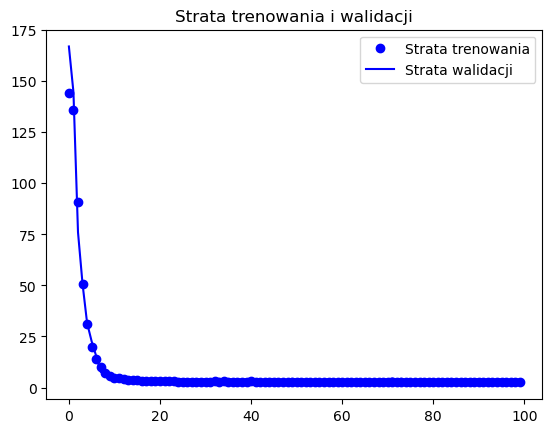

3.630695343017578


In [105]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

####################
print(min(val_loss))

l1_l2

In [99]:
from keras.models import Sequential
from keras.layers import Input, LSTM, Dense
from keras.regularizers import l1_l2
from keras.optimizers import Adam

l1_reg = 1e-5  # lambda karanie wag
l2_reg = 1e-5  # lambda karanie wag

model = Sequential([
    Input(shape=(n_steps, X_train.shape[2])),
    LSTM(64, activation='relu',return_sequences=True,kernel_regularizer=l1_l2(l1=l1_reg, l2=l2_reg)),
    LSTM(20, activation='relu',kernel_regularizer=l1_l2(l1=l1_reg, l2=l2_reg)),
    Dense(1)
])

optimizer = Adam(learning_rate=0.004170004462263622)
model.compile(optimizer=optimizer, loss='mae')


#########

history = model.fit(
    X_train, y_train,
    epochs=100,
    validation_data=(X_validation, y_validation)
)

Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - loss: 144.0224 - val_loss: 167.2693
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 137.6404 - val_loss: 149.5148
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 104.9211 - val_loss: 84.9183
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 57.8650 - val_loss: 54.2015
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 34.6304 - val_loss: 26.1331
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 19.4833 - val_loss: 17.4555
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 14.5239 - val_loss: 10.6348
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 9.6269 - val_loss: 7.7363
Epoch 9/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.0710 - val_loss: 6.2246
Epoch 10/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.4382 - val_loss: 6.0215
Epoch 11/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.4097 - val_loss: 5.7492
Epoch 12/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.7839 - val_loss: 3.9588
Epoch 70/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.7898 - val_loss: 3.8439
Epoch 71/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.7262 - val_loss: 4.1773
Epoch 72/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.8317 - val_loss: 4.0459
Epoch 73/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.8779 - val_loss: 3.9978
Epoch 74/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.6745 - val_loss: 4.2209
Epoch 75/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.3932 - val_loss: 4.1601
Epoch 76/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.8331 - val_loss: 3.9266
Epoch 77/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.8814 - val_loss: 3.7623
Epoch 78/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.7182 - val_loss: 3.9634
Epoch 79/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.6769 - val_loss: 3.7853
Epoch 80/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.5010 

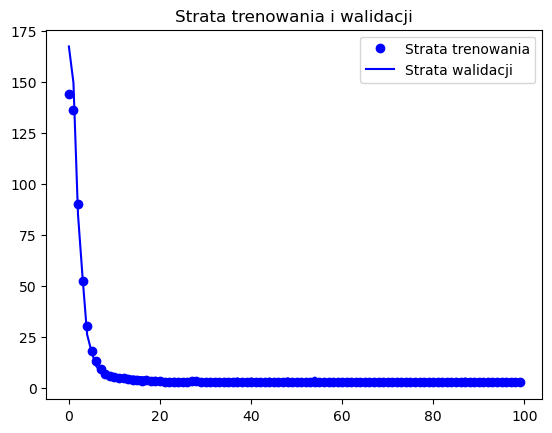

3.6436362266540527


In [100]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

####################
print(min(val_loss))

l1 i earlystopping

In [108]:
from keras.models import Sequential
from keras.layers import Input, LSTM, Dense
from keras.regularizers import l1
from keras.optimizers import Adam

# Ustal poziom regularyzacji L1
l1_reg = 1e-5  # lambda karanie wag

model = Sequential([
    Input(shape=(n_steps, X_train.shape[2])),
    LSTM(64, activation='relu',return_sequences=True,kernel_regularizer=l1(l1_reg)),
    LSTM(20, activation='relu',kernel_regularizer=l1(l1_reg)),
    Dense(1)
])

optimizer = Adam(learning_rate=0.004170004462263622)
model.compile(optimizer=optimizer, loss='mae')


In [109]:
from tensorflow.keras.callbacks import EarlyStopping

# Tworzenie callbacku EarlyStopping
early_stopping = EarlyStopping(
    monitor='val_loss',       # monitorowanie straty walidacyjnej
    patience=20,              #liczba epok bez poprawy, po których zatrzyma trenowanie
    restore_best_weights=True  # przywróć najlepsze wagi po zatrzymaniu
)

history = model.fit(
    X_train, y_train,
    epochs=100,
    validation_data=(X_validation, y_validation),
    callbacks=[early_stopping]
)

Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 144.4610 - val_loss: 167.0570
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 138.4855 - val_loss: 142.3024
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 91.5984 - val_loss: 66.0012
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 49.4523 - val_loss: 36.5362
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 26.1222 - val_loss: 24.2228
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 16.9894 - val_loss: 20.9840
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13.2118 - val_loss: 11.4013
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 9.1895 - val_loss: 6.7538
Epoch 9/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.9010 - val_loss: 6.1060
Epoch 10/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.2449 - val_loss: 5.8825
Epoch 11/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.5267 - val_loss: 5.6756
Epoch 12/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.8368 - val_loss: 3.6928
Epoch 70/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.7146 - val_loss: 3.8965
Epoch 71/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.6872 - val_loss: 3.8410
Epoch 72/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.5537 - val_loss: 3.8711
Epoch 73/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.7723 - val_loss: 3.8523
Epoch 74/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.7482 - val_loss: 3.7886
Epoch 75/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.7306 - val_loss: 3.6794
Epoch 76/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.7021 - val_loss: 3.7967
Epoch 77/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.6736 - val_loss: 4.0624
Epoch 78/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.7475 - val_loss: 3.6894
Epoch 79/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.7608 - val_loss: 4.1150


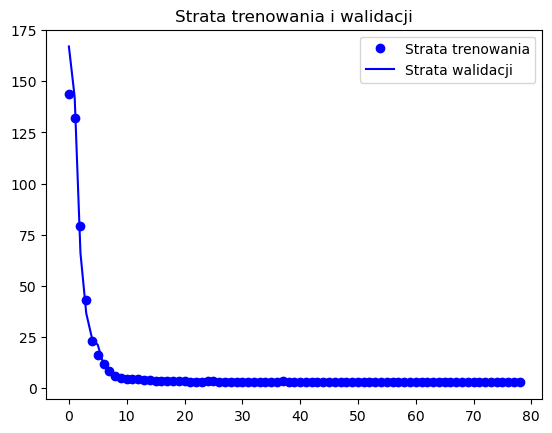

3.641112804412842


In [110]:
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(loss))

plt.figure()

plt.plot(epochs, loss, 'bo', label='Strata trenowania')
plt.plot(epochs, val_loss, 'b', label='Strata walidacji')
plt.title('Strata trenowania i walidacji')
plt.legend()

plt.show()

####################
print(min(val_loss))

### Actual vs predicted

In [118]:
def plot_predictions_with_error(true_data, predicted_data, title):
    plt.figure(figsize=(10, 12))
    
    # Flatten arrays to ensure compatibility with matplotlib
    true_data_flatten = true_data.flatten()
    predicted_data_flatten = predicted_data.flatten()
    
    # Calculate error
    error = true_data_flatten - predicted_data_flatten
    positive_error_std = np.std(error[error >= 0])
    negative_error_std = np.std(error[error < 0])
    mae = sum(np.abs(error))/len(error)
    print(f"Błąd MAE {mae}")
    # Plot true data vs. predicted data
    ax1 = plt.subplot(2, 1, 1)  # 2 rows, 1 column, 1st subplot
    ax1.plot(true_data_flatten, label='True Data')
    ax1.plot(predicted_data_flatten, label='Predicted Data', alpha=0.7)
    ax1.set_title(title)
    ax1.set_ylabel('Value')
    #ustawienie stałej skali na osi Y, gdy używam oryginalnej skali danych, nie mieszczacej się w zakresie [0,1]
    if true_data[0] > 1:
        ax1 = plt.gca()
        ax1.set_ylim([80, 300])
    ax1.legend()

In [119]:
train_pred = model.predict(X_train)
validation_pred = model.predict(X_validation)
test_pred = model.predict(X_test)

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step  
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


Training MAE
Błąd MAE 2.448818949780433
Validation MAE
Błąd MAE 3.6075633698445886
Test MAE
Błąd MAE 2.2581844329833984


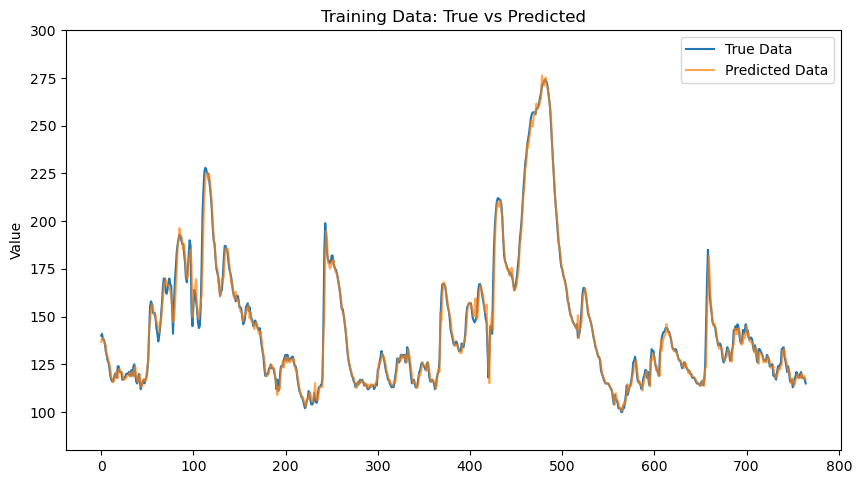

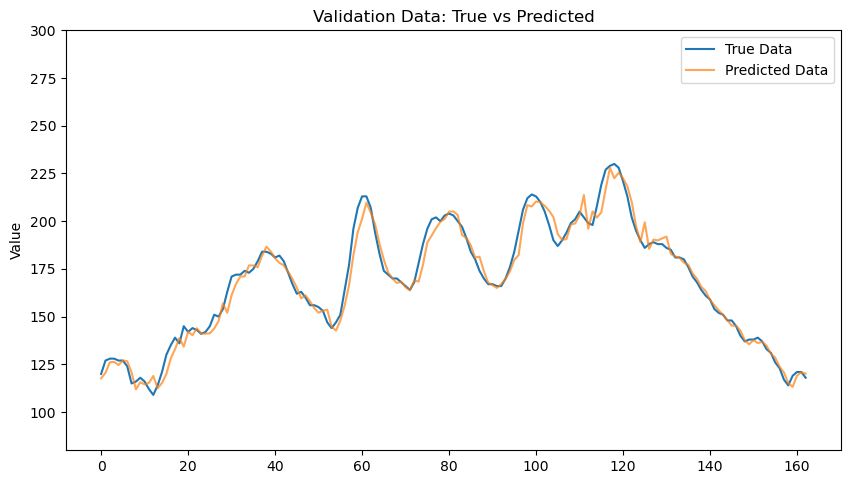

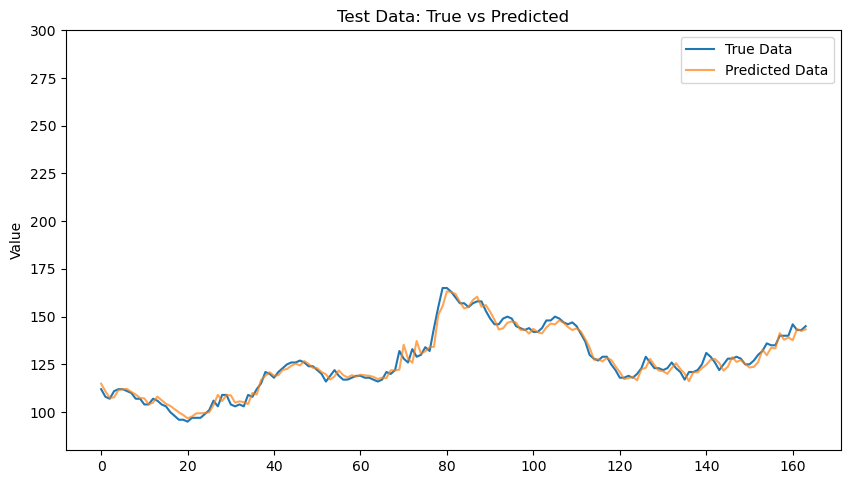

In [120]:
print("Training MAE")
plot_predictions_with_error(y_train, train_pred, 'Training Data: True vs Predicted')
print("Validation MAE")
plot_predictions_with_error(y_validation, validation_pred, 'Validation Data: True vs Predicted')
print("Test MAE")
plot_predictions_with_error(y_test, test_pred, 'Test Data: True vs Predicted')

In [121]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

def smape(y_true, y_pred):
    """
    Symmetric Mean Absolute Percentage Error
    """
    denominator = (np.abs(y_true) + np.abs(y_pred)) / 2.0
    diff = np.abs(y_true - y_pred) / denominator
    diff[denominator == 0] = 0.0  # Unikamy dzielenia przez 0
    return 100 * np.mean(diff)

def evaluate_model(y_true, y_pred):
    # Upewnij się, że dane są spłaszczone
    y_true = y_true.flatten()
    y_pred = y_pred.flatten()

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    smape_score = smape(y_true, y_pred)

    print(f"RMSE: {rmse:.4f}")
    print(f"R²: {r2:.4f}")
    print(f"sMAPE: {smape_score:.2f}%")


In [122]:
evaluate_model(y_test, test_pred)

RMSE: 2.9423
R²: 0.9683
sMAPE: 1.80%
